In [5]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

from materials import material_label

In [7]:
SCRIPT_DIR = Path.cwd()
DATA_ROOT = Path("/home/derksen/Desktop/geant4/Scintillation_Simulation_build/data")

In [14]:
CUMULATIVE_PHOTON_THRESHOLDS = [1, 5] + list(range(10, 141, 10))

COLUMN_NAMES = [
    "RunID",
    "EventID",
    "TrackID",
    "Hit",
    "GlobalTime",
    "TimeSinceZero",
    "TrackLenght",
    "PhotonEnergy",
    "PhotonFlightTime",
    "PhotonCreationTime",
    "Process",
    "NSideReflections",
    "ScintillatorLenght",
    "EmissionAngle",
    "Material",
    "ElectronEnergy",
]

# Nur diese Spalten werden gelesen, das spart Speicher
USECOLS = ["EventID", "Hit", "TimeSinceZero", "Process", "Material", "ElectronEnergy"]

DTYPES = {
    "EventID": "int32",
    "Hit": "category",
    "TimeSinceZero": "float64",
    "Process": "category",
    "Material": "category",
    "ElectronEnergy": "float32",
}

In [105]:
def format_energy(energy_mev):
    return f"{energy_mev / 1000:g} GeV" if energy_mev >= 1000 else f"{energy_mev:g} MeV"

def gauss(x, mean, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(x - mean) ** 2 / (2 * sigma ** 2))

def fit_gauss(times):
    # Gauss-Fit (def gauss) an das normierte Histogramm, Rückgabe: mean, sigma, mean_err, sigma_err
    hist, edges = np.histogram(times, bins="auto", density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])

    p0 = [np.mean(times), np.std(times, ddof=1)]
    try:
        popt, pcov = curve_fit(gauss, centers, hist, p0=p0)
    except (RuntimeError, ValueError):
        return (np.nan,) * 4

    # Unsichere Kovarianz (inf) wird zu NaN, dann fehlt nur der Fehlerbalken
    perr = np.sqrt(np.diag(pcov))
    perr = np.where(np.isfinite(perr), perr, np.nan)
    return popt[0], abs(popt[1]), perr[0], perr[1]

def threshold_times(df):
    # Zeit des N-ten Photons pro Event, Zeilen = EventID, Spalten = Schwelle
    times = df.loc[df["TimeSinceZero"] >= 0, ["EventID", "TimeSinceZero"]]
    times = times.sort_values(["EventID", "TimeSinceZero"])
    times["rank"] = times.groupby("EventID").cumcount() + 1
    times = times[times["rank"].isin(CUMULATIVE_PHOTON_THRESHOLDS)]
    table = times.pivot(index="EventID", columns="rank", values="TimeSinceZero")
    return table.reindex(columns=CUMULATIVE_PHOTON_THRESHOLDS)

def maximal_detected_photons(df):
    # Maximale Anzahl detektierter Photonen pro Event
    return df.max(axis=1)

def analyse_file(path):
    data = pd.read_csv(path, comment="#", header=None, names=COLUMN_NAMES, usecols=USECOLS, dtype=DTYPES)

    scintillation = data[data["Process"] == "Scintillation"]
    top = threshold_times(scintillation[scintillation["Hit"] == "top"])
    bottom = threshold_times(scintillation[scintillation["Hit"] == "bottom"])

    maximal_detected_photons_over_all_events = maximal_detected_photons(scintillation[scintillation["Hit"] == "top"]) + maximal_detected_photons(scintillation[scintillation["Hit"] == "bottom"])
    maximal_detected_photons_over_all_events = len(maximal_detected_photons_over_all_events)

    average_detected_photons_over_all_events = maximal_detected_photons_over_all_events / int(data["EventID"].nunique())

    # Events ohne Treffer auf einer Seite ergeben NaN
    difference = top - bottom

    rows = []
    for threshold in CUMULATIVE_PHOTON_THRESHOLDS:
        diff = difference[threshold].dropna().to_numpy(dtype=float)
        _, sigma, _, sigma_err = fit_gauss(diff) if len(diff) > 1 else (np.nan,) * 4

        # relative brightness of the threshold compared to the maximal detected photons
        relative_brightness = threshold / maximal_detected_photons_over_all_events if maximal_detected_photons_over_all_events > 0 else np.nan

        # relative brightness of the threshold compared to the average detected photons over all events
        relative_to_average_detected_photons_over_all_events = threshold / average_detected_photons_over_all_events if average_detected_photons_over_all_events > 0 else np.nan

        rows.append({
            "Threshold": threshold,
            "Events": len(diff),
            "Sigma_ps": sigma * 1000,
            "SigmaErr_ps": sigma_err * 1000,
            "RelativeBrightnessToMax": relative_brightness * 100, # in percent
            "RelativeBrightnessToAverage": relative_to_average_detected_photons_over_all_events * 100, # in percent
        })

    return {
        "material": str(data["Material"].iloc[0]),
        "energy_mev": float(data["ElectronEnergy"].iloc[0]),
        "n_events": int(data["EventID"].nunique()),
        "maximal_detected_photons_over_all_events": maximal_detected_photons_over_all_events,
        "average_detected_photons_over_all_events": average_detected_photons_over_all_events,
        "fits": pd.DataFrame(rows),
    }

In [106]:
results = {}

for path in sorted(DATA_ROOT.glob("EJ232/1GeV/70mm.csv")):
    length = float(path.name.removesuffix("mm.csv"))
    print(f"Loading CSV file: {path}")
    result = analyse_file(path)
    results[(length, result["material"], result["energy_mev"])] = result

if not results:
    raise SystemExit(f"No CSV files found under {DATA_ROOT}")

Loading CSV file: /home/derksen/Desktop/geant4/Scintillation_Simulation_build/data/EJ232/1GeV/70mm.csv


/tmp/ipykernel_538814/3163039483.py:34: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  return df.max(axis=1)


In [107]:
results

{(70.0, 'EJ232', 1000.0): {'material': 'EJ232',
  'energy_mev': 1000.0,
  'n_events': 1000,
  'maximal_detected_photons_over_all_events': 823034,
  'average_detected_photons_over_all_events': 823.034,
  'fits':     Threshold  Events    Sigma_ps  SigmaErr_ps  RelativeBrightnessToMax  \
  0           1    1000   43.753234     1.082858                 0.000122   
  1           5    1000   42.953450     0.965553                 0.000608   
  2          10    1000   46.587695     0.624405                 0.001215   
  3          20    1000   55.334285     1.496740                 0.002430   
  4          30    1000   57.045792     1.507186                 0.003645   
  5          40    1000   58.075888     1.423732                 0.004860   
  6          50    1000   64.305392     1.517859                 0.006075   
  7          60    1000   68.998206     1.619281                 0.007290   
  8          70    1000   74.479111     2.069539                 0.008505   
  9          80    10

In [111]:
key = (70.0, 'EJ232', 1000.0)

material = results[key]['material']
energy = results[key]['energy_mev']
n_events = results[key]['n_events']
fits = results[key]['fits']

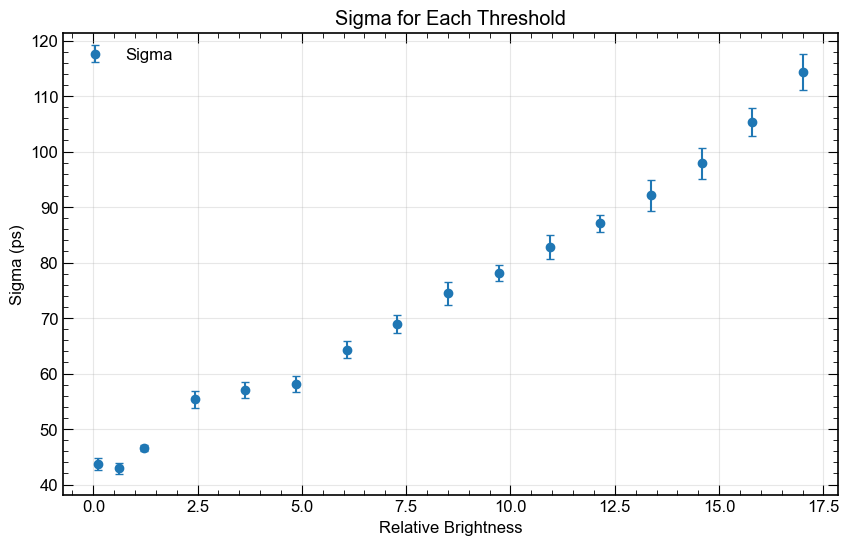

In [112]:
# now plot the sigma for each threshold (relative to max and average)

def plot_sigma(fits):
    relative_brightness = fits["RelativeBrightnessToAverage"]
    sigma = fits["Sigma_ps"]
    sigma_err = fits["SigmaErr_ps"]

    plt.figure(figsize=(10, 6))
    plt.errorbar(relative_brightness, sigma, yerr=sigma_err, fmt='o', label="Sigma")
    plt.xlabel("Relative Brightness")
    plt.ylabel("Sigma (ps)")
    plt.title("Sigma for Each Threshold")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_sigma(fits)